# 수정된 전처리 함수 작동 검증

- **상태**: 완료
- **작성자**: byhyun
- **실행일**: 2026-11-20
- **목적**: 수정·추가된 `scripts/preprocessing.py` 함수(`load_binary_mask` NumPy 정수 허용, `make_ela` 잘못된 `scale` 예외 처리, `pad_image`·`unpad_image` 32배수 우하단 패딩 및 원본 크기 복원)의 Colab 동작과 실제 AutoSplice 이미지 패딩 정합성 확인
- **관련 보고서**: [보고서](../../docs/eda/EXP_byhyun_002_preprocessing_padding_check.md)

### - 목적 및 변경 사항

`EXP_byhyun_001` 이후 팀 합의로 확정한 공통 전처리·패딩 규약과 입력 예외 처리 보완이 `scripts/preprocessing.py`에 반영되었으며, 본 노트북은 Colab 환경에서 해당 함수들의 정상 동작을 검증한다.

1. **입력 예외 처리 보완**
   - `load_binary_mask`: `foreground_value`에 NumPy 정수(`np.integer`)를 허용하고, 불리언(`bool`)은 거부함.
   - `make_ela`: `scale`에 불리언, 문자열, 복소수, 무한대, 비양수 입력 시 `ValueError`를 발생시킴.
2. **평가용 우하단 제로 패딩·언패딩 함수 추가**
   - `pad_image`: 좌측 상단 `(0, 0)`을 고정한 채 높이·너비를 `multiple`(기본 `32`)의 배수로 올림해 우하단에 `0` 패딩을 추가함.
   - `unpad_image`: 모델 추론 후 우하단 패딩을 제거하고 `original_size` 기준 원본 해상도로 잘라내어 원본 마스크와 비교할 수 있도록 함.

## 1. 실행 환경 및 공통 코드 버전 확인

Google Drive를 마운트하고 공유 경로(`AI_Forensics/project`)를 `sys.path`에 등록한다. 재현성을 위해 실행 환경의 Python·주요 패키지 버전과 로드할 `scripts/preprocessing.py`, `scripts/datasets.py`, 분할 CSV의 SHA-256 해시를 출력한다.

In [1]:
import hashlib
import os
import platform
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import PIL
from google.colab import drive

drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/AI_Forensics/project")
DATA_ROOT = Path("/content/drive/MyDrive/AI_Forensics/datasets")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

prep_path = PROJECT_ROOT / "scripts" / "preprocessing.py"
prep_sha256 = hashlib.sha256(prep_path.read_bytes()).hexdigest()

print(f"Python: {platform.python_version()}")
print(f"NumPy: {np.__version__}, Pillow: {PIL.__version__}")
for name, path in [
    ("preprocessing.py", prep_path),
    ("datasets.py", PROJECT_ROOT / "scripts" / "datasets.py"),
    ("autosplice_seed42.csv", PROJECT_ROOT / "scripts" / "splits" / "autosplice_seed42.csv"),
]:
    print(f"{name} SHA-256: {hashlib.sha256(path.read_bytes()).hexdigest()}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Python: 3.13.18
NumPy: 2.4.6, Pillow: 11.3.0
preprocessing.py SHA-256: 73ce7fa0aee3f2b901a9ab04d430ff8ae2bcaa7262005600f6b08f04b95c652f
datasets.py SHA-256: 435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88
autosplice_seed42.csv SHA-256: f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e


## 2. 합성 입력 단위 검증

실제 데이터셋을 다루기 전에 합성 배열을 이용해 다음 세 가지 항목을 단위 검증한다.

- **전경값 타입 처리 (`load_binary_mask`)**: `np.int64(255)` 전달 시 정상 이진화 여부 및 `bool` 전달 시 `ValueError` 발생 여부 확인
- **배율 예외 처리 (`make_ela`)**: `scale`에 `True`, `False`, `"15"`, `1+2j`, `inf`, `-1.0` 전달 시 모두 `ValueError`로 일관되게 차단되는지 확인
- **패딩·언패딩 무결성 (`pad_image`, `unpad_image`)**:
  - 비배수 크기 `(45, 53, 3)` 입력 시 `(64, 64, 3)`으로 우하단만 `0` 패딩되고 원본 크기 `(45, 53)`을 반환하는지 확인
  - `unpad_image` 적용 시 원본 배열과 픽셀 단위로 일치하며, 반환 배열 수정 시 패딩 배열이 변하지 않는지(복사본 독립성) 확인
  - 이미 `32`의 배수인 크기 `(64, 96)` 입력 시 불필요한 추가 패딩 없이 원본 크기 그대로 반환되는지 확인

In [2]:
import tempfile
from PIL import Image
from scripts.preprocessing import (
    crop_pair,
    load_binary_mask,
    load_rgb,
    make_ela,
    pad_image,
    unpad_image,
)

# 1. load_binary_mask: NumPy 정수(np.int64) 허용 및 불리언 거부 확인
with tempfile.TemporaryDirectory() as tmp:
    mask_path = Path(tmp) / "test_mask.png"
    dummy_mask = np.zeros((40, 50), dtype=np.uint8)
    dummy_mask[10:20, 15:30] = 255
    Image.fromarray(dummy_mask).save(mask_path)

    loaded_mask = load_binary_mask(mask_path, foreground_value=np.int64(255))
    assert loaded_mask.shape == (40, 50) and loaded_mask.dtype == np.uint8
    assert int(loaded_mask.sum()) == 150

    try:
        load_binary_mask(mask_path, foreground_value=True)
        raise AssertionError("bool foreground_value가 허용됨")
    except ValueError:
        pass

# 2. make_ela: scale 불리언·문자열·복소수 ValueError 확인
dummy_rgb = np.random.default_rng(42).integers(0, 256, size=(45, 53, 3), dtype=np.uint8)
for invalid_scale in (True, False, "15", 1 + 2j, float("inf"), -1.0):
    try:
        make_ela(dummy_rgb, quality=90, scale=invalid_scale, subsampling=2)
        raise AssertionError(f"잘못된 scale이 허용됨: {invalid_scale}")
    except ValueError:
        pass

# 3. pad_image & unpad_image: 32배수 우하단 패딩, 이미 배수인 경우, 원본 크기 복원 및 복사본 독립성
padded_rgb, orig_size = pad_image(dummy_rgb, multiple=32)
assert padded_rgb.shape == (64, 64, 3) and orig_size == (45, 53)
assert np.array_equal(padded_rgb[:45, :53], dummy_rgb)
assert int(padded_rgb[45:, :].sum()) == 0 and int(padded_rgb[:, 53:].sum()) == 0

unpadded_rgb = unpad_image(padded_rgb, original_size=orig_size)
assert unpadded_rgb.shape == (45, 53, 3) and np.array_equal(unpadded_rgb, dummy_rgb)

# 복사본 독립성 확인
unpadded_rgb[0, 0, 0] = 123
assert padded_rgb[0, 0, 0] == dummy_rgb[0, 0, 0]

# 이미 32의 배수인 입력 확인
exact_arr = np.ones((64, 96), dtype=np.float32)
exact_padded, exact_size = pad_image(exact_arr, multiple=32)
assert exact_padded.shape == (64, 96) and exact_size == (64, 96)

print("합성 입력 검증 통과: load_binary_mask, make_ela, pad_image, unpad_image 정상 동작 확인")

합성 입력 검증 통과: load_binary_mask, make_ela, pad_image, unpad_image 정상 동작 확인


## 3. 실제 AutoSplice 데이터 평가 파이프라인 검증

팀 합의로 확정한 평가 전처리·후처리 순서가 실제 다양한 해상도의 이미지에서도 오차 없이 동작하는지 확인한다. 테스트 데이터는 사용하지 않고 `autosplice_seed42.csv`의 `val` 분할 조작 이미지 361장 전체를 사용한다.

1. 원본 해상도에서 RGB·마스크를 읽고 ELA(`quality=90, scale=15, subsampling=2`)를 선계산한다.
2. `pad_image(..., multiple=32)`로 ELA와 마스크의 높이와 너비를 `32`의 배수로 맞춘다.
3. 모델 출력 예측 맵 대신 패딩된 마스크에 `unpad_image(..., original_size=orig_size)`를 적용했을 때 원본 정답 마스크와 크기 및 픽셀 값이 100% 일치하는지 검증한다.

패딩된 ELA의 좌측 상단이 원본 ELA와 같고 나머지는 모두 0인지, 패딩이 필요했던 이미지가 몇 장인지도 함께 확인한다.

In [3]:
from scripts.datasets import autosplice_records, prepare_dataset_zip, sha256
from scripts.preprocessing import load_rgb

AUTOSPLICE_ZIP = DATA_ROOT / "AutoSplice" / "AutoSplice.zip"
AUTOSPLICE_HASH = "0d94e2df6842f44c11e21ee207707c49fd9717ec89048bd6f28fc1e07c4a5e36"
SPLIT_CSV = PROJECT_ROOT / "scripts" / "splits" / "autosplice_seed42.csv"

data_dir = prepare_dataset_zip(
    source=AUTOSPLICE_ZIP,
    runtime_zip=Path("/content/AutoSplice.zip"),
    destination=Path("/content/datasets"),
    expected_hash=AUTOSPLICE_HASH,
)
autosplice_dir = data_dir / "AutoSplice"

records = autosplice_records(autosplice_dir, SPLIT_CSV, quality=100)
val_forged = [r for r in records if r["split"] == "val" and r["kind"] == "manipulated"]

need_pad = 0
for rec in val_forged:
    rgb = load_rgb(rec["image_path"])
    mask = load_binary_mask(rec["mask_path"], foreground_value=255)
    ela = make_ela(rgb, quality=90, scale=15, subsampling=2)

    padded_ela, orig_size = pad_image(ela, multiple=32)
    padded_mask, _ = pad_image(mask, multiple=32)
    h, w = orig_size

    assert orig_size == rgb.shape[:2] == mask.shape
    assert padded_ela.shape[0] % 32 == 0 and padded_ela.shape[1] % 32 == 0
    assert padded_ela.shape[:2] == padded_mask.shape
    assert np.array_equal(padded_ela[:h, :w], ela)
    assert padded_ela[h:].sum() == 0 and padded_ela[:, w:].sum() == 0
    assert np.array_equal(unpad_image(padded_mask, original_size=orig_size), mask)
    need_pad += int(h % 32 != 0 or w % 32 != 0)

print(f"val 조작 이미지 {len(val_forged)}장 모두 통과, 패딩이 필요했던 이미지 {need_pad}장")

AutoSplice 기존 해제 파일 사용
val 조작 이미지 361장 모두 통과, 패딩이 필요했던 이미지 250장


## 4. 패딩·언패딩 결과 시각 확인

패딩이 가장 많이 붙는 이미지, 패딩이 필요한 이미지 중 중간 정도인 이미지, 이미 32의 배수라 패딩이 없는 이미지를 1장씩 골라, 좌측 상단 (0, 0)이 고정된 채 우하단에만 0 여백이 추가되는지 시각적으로 확인한다. 빨간 상자는 원본 영역이다. 언패딩 후 마스크의 복원 일치는 3절의 검사로 확인했다.

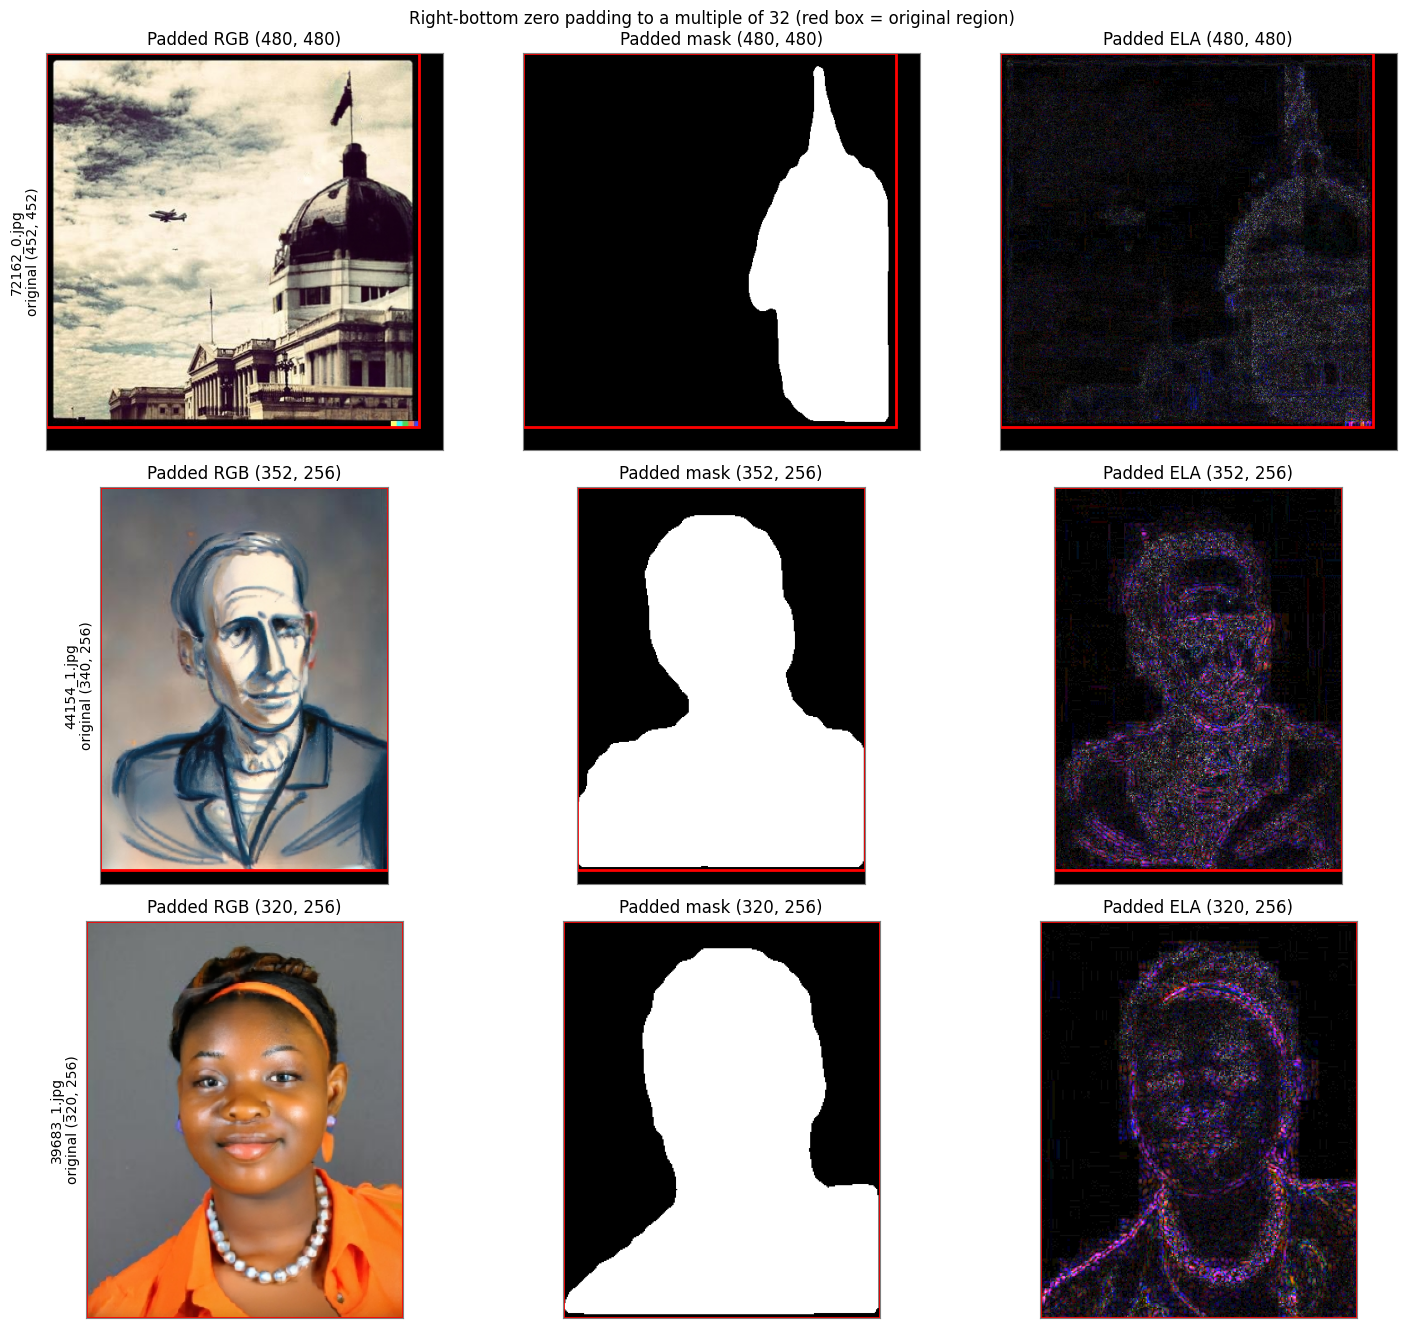

In [5]:
def pad_amount(rec):
    with Image.open(rec["image_path"]) as im:
        w, h = im.size
    return (-h) % 32 + (-w) % 32

needs = sorted([r for r in val_forged if pad_amount(r) > 0], key=pad_amount, reverse=True)
exact = [r for r in val_forged if pad_amount(r) == 0]
samples = [needs[0], needs[len(needs) // 2]] + exact[:1]

fig, axes = plt.subplots(len(samples), 3, figsize=(15, 4.5 * len(samples)), squeeze=False)
for row, sample in zip(axes, samples):
    rgb = load_rgb(sample["image_path"])
    mask = load_binary_mask(sample["mask_path"], foreground_value=255)
    ela = make_ela(rgb, quality=90, scale=15, subsampling=2)
    h, w = rgb.shape[:2]
    padded = [pad_image(a, multiple=32)[0] for a in (rgb, mask, ela)]

    for ax, img, cmap, name in zip(row, padded, (None, "gray", None), ("Padded RGB", "Padded mask", "Padded ELA")):
        ax.imshow(img, cmap=cmap, vmin=0 if cmap else None, vmax=1 if cmap else None)
        ax.add_patch(plt.Rectangle((-0.5, -0.5), w, h, fill=False, edgecolor="red", linewidth=2))
        ax.set_title(f"{name} {img.shape[:2]}")
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_edgecolor("gray")
    row[0].set_ylabel(f"{Path(sample['image_path']).name}\noriginal {(h, w)}")

fig.suptitle("Right-bottom zero padding to a multiple of 32 (red box = original region)")
plt.tight_layout()
plt.show()